# Validation 1 — Nhân tố thị trường: thứ tự EASE có phải chỉ là "độ nhạy với thị trường"? (20 mã)

Processing cho thấy mọi cặp mã thuộc vùng **nguyên nhân chung**. Notebook này đưa nguyên nhân chung vào dưới hai dạng:

| Biến | Định nghĩa | Ghi chú nhân quả |
|---|---|---|
| **VNI** | lợi suất log VN-Index (đã lọc GARCH) | Bình quân gia quyền vốn hoá, **chứa chính 20 mã** → một phần là *hệ quả* của các mã |
| **MKT$_{-i}$** | với mã $i$: trung bình đều $z$ của 19 mã còn lại (leave-one-out) | Không chứa $i$ → tránh tương quan cơ học; khác nhau theo từng mã |

**Câu hỏi:** (1) thị trường có hành xử như **nguyên nhân** ở đuôi không? (2) thứ tự EASE có trùng thứ tự **hệ số tải thị trường**
$\beta_i$ không — với 20 mã giờ có thể kiểm định bằng tương quan hạng? (3) sau khi loại thị trường, còn lại cấu trúc đuôi nào?

**Chạy trước:** `python src/download_market.py` (VN-Index) và `notebook/Processing/02_ease_real_data.ipynb` (bảng bootstrap).

## 0. Thiết lập và chuẩn bị dữ liệu

Lọc GARCH(1,1)-t cho 20 mã + VN-Index, lưu `data/processed/garch_std_resid_market.parquet` cho các notebook Validation và Calibration.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "validation"                      # hình → report/figure/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

import validation as V
from scipy import stats
P = len(SYMBOLS)
OFF = ~np.eye(P, dtype=bool)

import download_market as DM
con = U.connect()
r = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS].dropna()
r.index = pd.to_datetime(r.index)
vni = DM.index_log_returns(pd.read_csv(ROOT / "data" / "raw" / "vnindex_ohlcv.csv"))
R = pd.concat([r, vni], axis=1, join="inner").dropna()
Z, gpar = TP.garch_standardize(R)
Z = Z.dropna()
Z.to_parquet(ROOT / "data" / "processed" / "garch_std_resid_market.parquet")
z = Z[SYMBOLS]; n, K = len(z), CT.default_k(len(z))
E, beta = V.loo_market_adjust(z)
print(f"{len(Z)} phiên chung; GARCH hội tụ ở cả {Z.shape[1]} chuỗi: {bool(gpar['converged'].all())}; k = {K}")

2118 phiên chung; GARCH hội tụ ở cả 21 chuỗi: True; k = 21


## 1. Thị trường có phải nguyên nhân ở đuôi?

**Tính gì:** cho mỗi mã $i$, hệ số đuôi sập hai chiều giữa VNI và $i$: $\hat\Gamma^-_{\text{VNI}\to i}$, $\hat\Gamma^-_{i\to\text{VNI}}$, và $\hat\Psi$ hai chiều.

**Kỳ vọng nếu thị trường là nguyên nhân** (Định lý 1): $\Gamma^-_{\text{VNI}\to i} \to 1 > \Gamma^-_{i\to\text{VNI}}$. Vì VNI còn là
**tổng có trọng số** của các mã, mã vốn hoá lớn (VIC, VHM, VCB…) cũng là "nguyên nhân" của VNI — chiều ngược lại có thể cao ở các mã này.

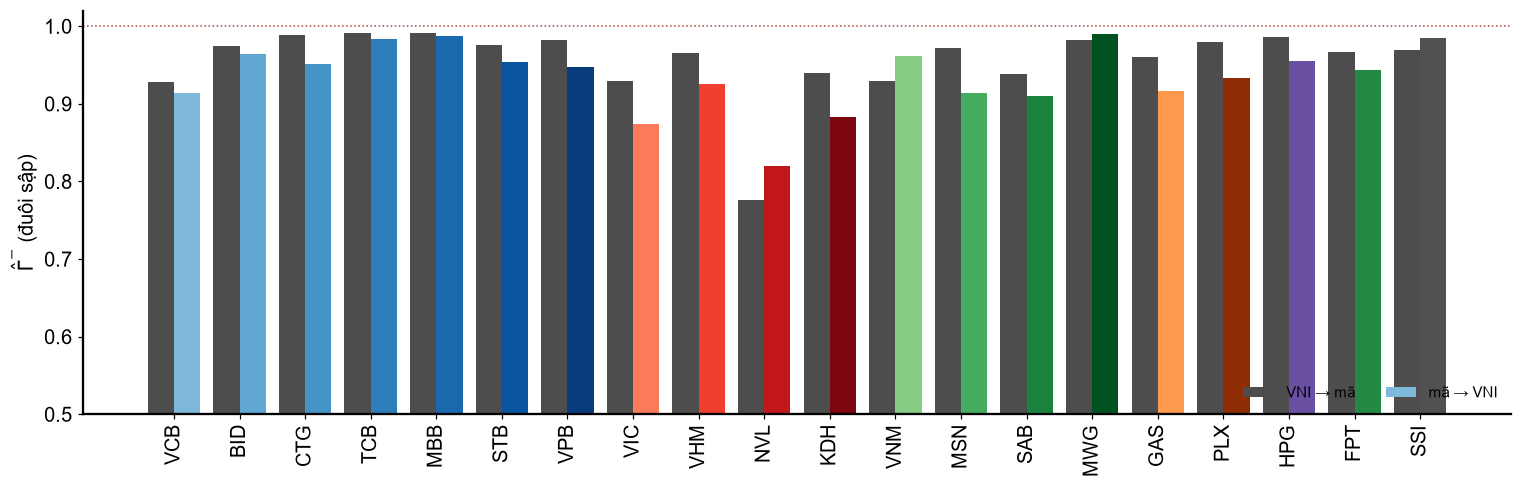

Số mã có Γ⁻ VNI→mã > mã→VNI: 16/20; Γ⁻ VNI→mã trong [0.78, 0.99]


,Ψ VNI→mã,Ψ mã→VNI,Γ⁻ VNI→mã,Γ⁻ mã→VNI
VCB,0.832,0.779,0.928,0.915
BID,0.873,0.823,0.974,0.964
CTG,0.907,0.843,0.989,0.952
TCB,0.881,0.841,0.992,0.984
MBB,0.914,0.871,0.991,0.988
STB,0.878,0.765,0.976,0.954
VPB,0.862,0.825,0.982,0.947
VIC,0.818,0.795,0.930,0.874
VHM,0.849,0.803,0.965,0.926
NVL,0.669,0.676,0.776,0.819


In [2]:
P21 = CT.tail_coef_matrix(Z[SYMBOLS + ["VNI"]], k=K, kind="psi")
L21 = CT.tail_coef_matrix(Z[SYMBOLS + ["VNI"]], k=K, kind="gamma_lower")
mk = pd.DataFrame({"Ψ VNI→mã": P21.loc["VNI", SYMBOLS], "Ψ mã→VNI": P21.loc[SYMBOLS, "VNI"],
                   "Γ⁻ VNI→mã": L21.loc["VNI", SYMBOLS], "Γ⁻ mã→VNI": L21.loc[SYMBOLS, "VNI"]})
U.save_table(mk, "01_market_tail_coef", FOLDER)

fig, ax = plt.subplots(figsize=(14, 4.6))
x = np.arange(P); w = 0.4
ax.bar(x - w / 2, mk["Γ⁻ VNI→mã"], w, color=PAL["gray_dark"], label="VNI → mã")
ax.bar(x + w / 2, mk["Γ⁻ mã→VNI"], w, color=[COL[s] for s in SYMBOLS], label="mã → VNI")
ax.axhline(1, color=PAL["red_strong"], ls=":", lw=1)
ax.set_xticks(x, SYMBOLS, rotation=90); ax.set_ylim(0.5, 1.02); ax.set_ylabel(r"$\hat\Gamma^{-}$ (đuôi sập)")
ax.legend(fontsize=10, loc="lower right", ncol=2)
U.finalize_figure(fig, "01_market_tail_coef", folder=FOLDER); plt.show()
print(f"Số mã có Γ⁻ VNI→mã > mã→VNI: {(mk['Γ⁻ VNI→mã'] > mk['Γ⁻ mã→VNI']).sum()}/{P}; "
      f"Γ⁻ VNI→mã trong [{mk['Γ⁻ VNI→mã'].min():.2f}, {mk['Γ⁻ VNI→mã'].max():.2f}]")
mk.round(3)

### Phân tích

_(điền sau khi chạy)_

## 2. Thứ tự EASE so với hệ số tải thị trường

**Tính gì:** $\hat\beta_i$ từ hồi quy $z_{i,t} = a_i + \beta_i\,\text{MKT}_{-i,t} + e_{i,t}$; vị trí trung bình của mã $i$ trong thứ tự EASE qua
500 mẫu bootstrap (bảng `02_bootstrap_rank_freq.csv` của Processing): $\overline{\text{pos}}_i = \sum_r r\,\hat P(\text{mã } i \text{ ở vị trí } r)$.
**Giả thuyết thay thế:** trong mô hình một nhân tố không có nhân quả giữa các mã, EASE xếp mã theo thứ tự **tăng dần** $\beta_i$
(mã ít nhạy thị trường ít bị "kéo theo" nên lên đầu). Đo bằng tương quan hạng Spearman $\rho_S$ và kiểm định $H_0: \rho_S = 0$.

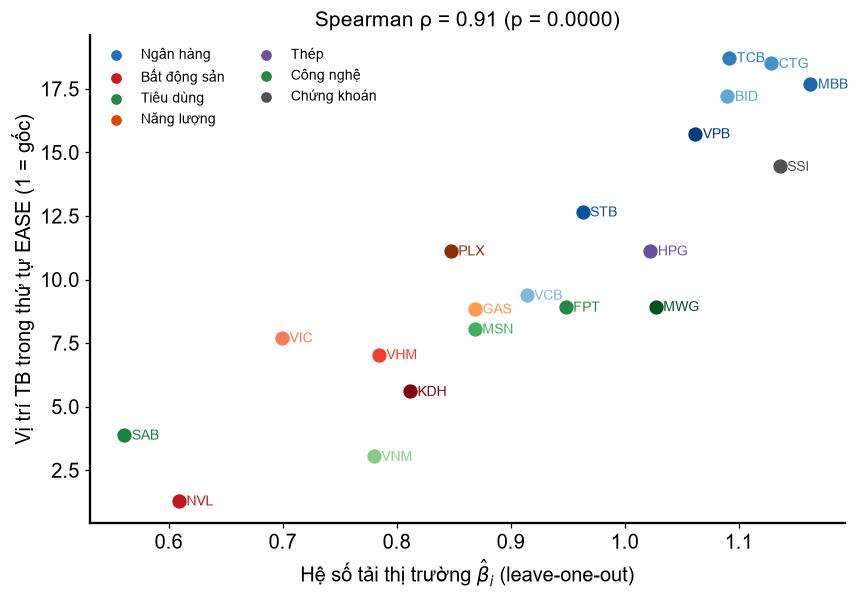

,beta_LOO,vi_tri_TB_bootstrap,nganh
SAB,0.561,3.886,Tiêu dùng
NVL,0.609,1.296,Bất động sản
VIC,0.699,7.710,Bất động sản
VNM,0.780,3.050,Tiêu dùng
VHM,0.784,7.050,Bất động sản
KDH,0.812,5.604,Bất động sản
PLX,0.847,11.132,Năng lượng
MSN,0.868,8.058,Tiêu dùng
GAS,0.869,8.846,Năng lượng
VCB,0.914,9.390,Ngân hàng


In [3]:
rf = pd.read_csv(ROOT / "report" / "table" / "processing" / "02_bootstrap_rank_freq.csv", index_col=0, encoding="utf-8-sig")
mean_pos = (rf * np.arange(1, rf.shape[1] + 1)).sum(axis=1).loc[SYMBOLS]
rho, pval = stats.spearmanr(beta.loc[SYMBOLS], mean_pos)
tab = pd.DataFrame({"beta_LOO": beta, "vi_tri_TB_bootstrap": mean_pos, "nganh": [U.SECTOR[s] for s in SYMBOLS]})
U.save_table(tab, "01_beta_vs_position", FOLDER)

fig, ax = plt.subplots(figsize=(8, 5.6))
for s in SYMBOLS:
    ax.scatter(beta[s], mean_pos[s], s=70, color=COL[s], zorder=3)
    ax.annotate(s, (beta[s], mean_pos[s]), xytext=(5, -3), textcoords="offset points", fontsize=9, color=COL[s])
for sec in U.SECTORS:
    ax.scatter([], [], color=U.SECTOR_COLORS[sec], label=sec)
ax.legend(fontsize=9, loc="upper left", ncol=2)
ax.set_xlabel(r"Hệ số tải thị trường $\hat\beta_i$ (leave-one-out)"); ax.set_ylabel("Vị trí TB trong thứ tự EASE (1 = gốc)")
ax.set_title(f"Spearman ρ = {rho:.2f} (p = {pval:.4f})")
U.finalize_figure(fig, "01_beta_vs_position", folder=FOLDER); plt.show()
tab.sort_values("beta_LOO").round(3)

### Phân tích

_(điền sau khi chạy)_

## 3. EASE sau khi loại thị trường

**Tính gì:** phần dư $e_{i,t}$ (mục 2); ma trận $\hat\Psi$ của $e$, thứ tự EASE, độ ổn định bootstrap ($B = 300$).
Nếu có lan truyền cú sốc trực tiếp giữa các mã, nó vẫn còn sau khi loại sốc chung; nếu chỉ có thị trường, $\hat\Psi$ của $e$ về gần $1/2$.
Lưu ý: chỉ loại **một** nhân tố thị trường — nhân tố **ngành** (ví dụ ngân hàng) vẫn còn trong $e$.

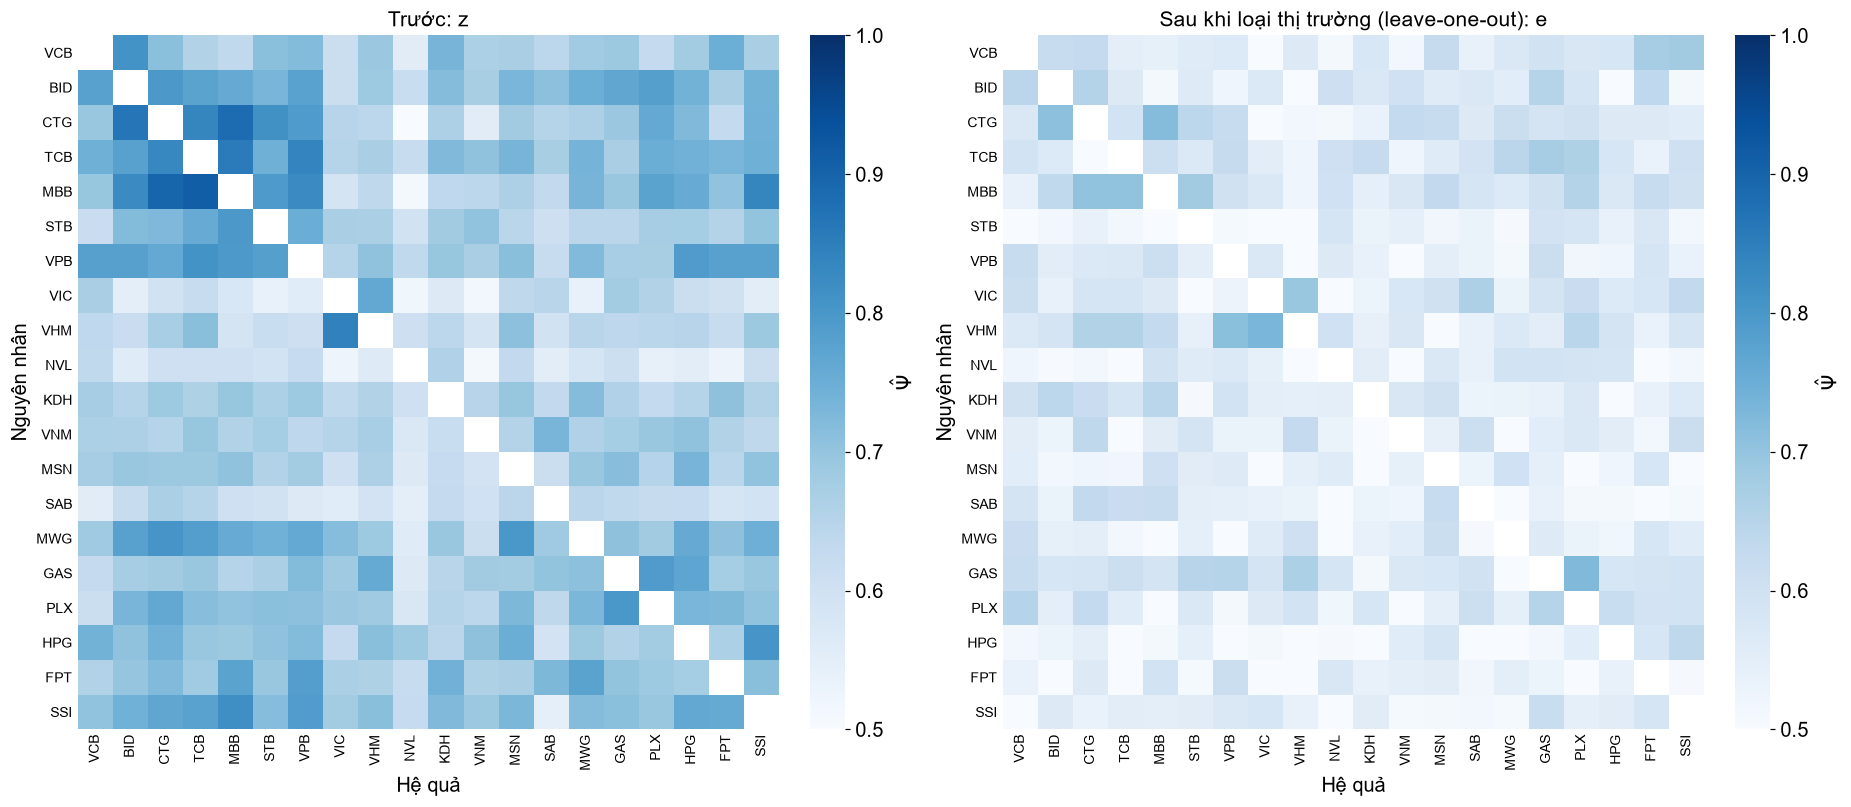

Ψ̂ trung bình: z = 0.681 → e = 0.560; trong e: cùng ngành 0.578, khác ngành 0.556
Thứ tự EASE trên e: NVL → HPG → KDH → VNM → MSN → MWG → VCB → SSI → FPT → SAB → GAS → PLX → STB → VHM → VIC → VPB → TCB → CTG → MBB → BID | lặp lại trong bootstrap: 0%
Gốc phổ biến nhất trên e: {'KDH': 0.19, 'NVL': 0.17, 'VNM': 0.14}


In [4]:
Pz, Pe = CT.tail_coef_matrix(z, k=K), CT.tail_coef_matrix(E, k=K)
order_e = CT.ease(Pe)
boot_e = TP.bootstrap_coef(E, k=K, kind="psi", B=300, seed=11)
orders_e = [CT.ease(pd.DataFrame(m, index=SYMBOLS, columns=SYMBOLS)) for m in boot_e]
rf_e = V.order_frequency(orders_e, SYMBOLS)
U.save_table(Pe, "01_psi_residual", FOLDER); U.save_table(rf_e, "01_residual_rank_freq", FOLDER)

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
U.make_heatmap(axes[0], Pz, cmap="Blues", vmin=0.5, vmax=1, fmt=None, tick_fontsize=9, cbar_label=r"$\hat\Psi$", title="Trước: z")
U.make_heatmap(axes[1], Pe, cmap="Blues", vmin=0.5, vmax=1, fmt=None, tick_fontsize=9, cbar_label=r"$\hat\Psi$",
               title="Sau khi loại thị trường (leave-one-out): e")
for ax in axes:
    ax.set_xlabel("Hệ quả"); ax.set_ylabel("Nguyên nhân")
U.finalize_figure(fig, "01_residual_ease", folder=FOLDER); plt.show()
sec = np.array([U.SECTOR[s] for s in SYMBOLS]); same = (sec[:, None] == sec[None, :]) & OFF
print(f"Ψ̂ trung bình: z = {Pz.values[OFF].mean():.3f} → e = {Pe.values[OFF].mean():.3f}; "
      f"trong e: cùng ngành {Pe.values[same].mean():.3f}, khác ngành {Pe.values[OFF & ~same].mean():.3f}")
print("Thứ tự EASE trên e:", " → ".join(order_e), f"| lặp lại trong bootstrap: {np.mean([o == order_e for o in orders_e]):.0%}")
print("Gốc phổ biến nhất trên e:", rf_e[1].sort_values(ascending=False).head(3).round(2).to_dict())

### Phân tích

_(điền sau khi chạy)_

## 4. Kết luận

_(điền sau khi chạy)_